<a href="https://colab.research.google.com/github/dbonacorsi/AML-Basic/blob/main/AMLBas_2_DataPrep_ExploreData_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explore your data with descriptive statistics

***The time spent in understanding your data (BEFORE APPLYING ANY ML TECHNIQUES) is time well spent***.

In this notebook we start exploring **EDA** (**exploratory data analysis**): the process of analyzing and understanding your dataset before building models.

Suggestions and guidelines may differ, but here is what we use as a checklist:

1. Look at the raw data
1. Dimensions
1. Data types
1. Descriptive statistics
1. Distribution of instances across classes
1. Correlations
1. Skews

## 1. Raw data

In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/dbonacorsi/AML-Basic/refs/heads/main/datasets/pima-indians-diabetes.data.csv'

names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
data = pd.read_csv(url, names=names)
data

,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


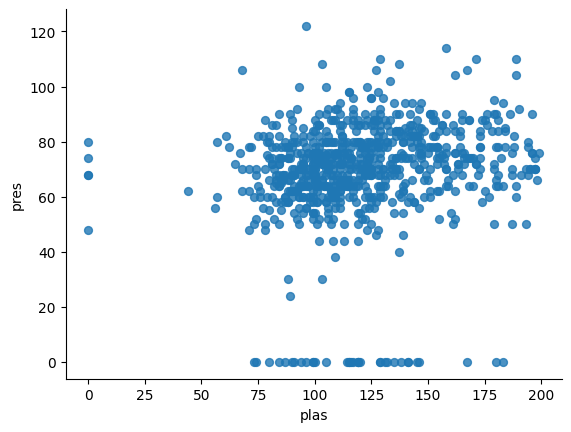

In [2]:
# @title plas vs pres

from matplotlib import pyplot as plt
data.plot(kind='scatter', x='plas', y='pres', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

More details can be found e.g. at https://www.kaggle.com/uciml/pima-indians-diabetes-database/data, and are summarized below:

    Pregnancies = Number of times pregnant
    Glucose = Plasma glucose concentration a 2 hours in an oral glucose tolerance test numeric
    BloodPressure = Diastolic blood pressure (mm Hg)
    SkinThickness = Triceps skin fold thickness (mm)
    Insulin = 2-Hour serum insulin (mu U/ml)
    BMI = Body mass index (weight in kg/(height in m)^2)
    DiabetesPedigreeFunction = Diabetes pedigree function
    Age = Age (years)
    Outcome = Class variable (0 or 1)

This is the mapping to actual code short names, in the same order:

    'preg'
    'plas'
    'pres'
    'skin'
    'test'
    'mass'
    'pedi'
    'age'
    'class'

## 2. Dimensions

In [3]:
shape = data.shape
shape

(768, 9)

## 3. Data types

In [4]:
types = data.dtypes
print(types)

preg       int64
plas       int64
pres       int64
skin       int64
test       int64
mass     float64
pedi     float64
age        int64
class      int64
dtype: object


## 4. Descriptive statistics

Help on pandas set_option [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.set_option.html).


In [5]:
from pandas import set_option

set_option('display.width', 200)
set_option('display.max_rows', 500)
set_option('display.max_columns', 500)
#set_option('precision', 3)

In [6]:
description = data.describe()
print(description)

             preg        plas        pres        skin        test        mass        pedi         age       class
count  768.000000  768.000000  768.000000  768.000000  768.000000  768.000000  768.000000  768.000000  768.000000
mean     3.845052  120.894531   69.105469   20.536458   79.799479   31.992578    0.471876   33.240885    0.348958
std      3.369578   31.972618   19.355807   15.952218  115.244002    7.884160    0.331329   11.760232    0.476951
min      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000    0.078000   21.000000    0.000000
25%      1.000000   99.000000   62.000000    0.000000    0.000000   27.300000    0.243750   24.000000    0.000000
50%      3.000000  117.000000   72.000000   23.000000   30.500000   32.000000    0.372500   29.000000    0.000000
75%      6.000000  140.250000   80.000000   32.000000  127.250000   36.600000    0.626250   41.000000    1.000000
max     17.000000  199.000000  122.000000   99.000000  846.000000   67.100000    2.42000

What can we learn from this simple overview of our data?
*   Are there missing entries anywhere?
*   Are the values of the features on the same scales?


## 5. Class distribution
(only for classification problems)

In [7]:
class_counts = data.groupby('class').size()
print(class_counts)

class
0    500
1    268
dtype: int64


## 6. Correlations between attributes

In [8]:
set_option('display.width', 100)
#set_option('precision', 3)

correlations = data.corr(method='pearson')
correlations

,preg,plas,pres,skin,test,mass,pedi,age,class
preg,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
plas,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
pres,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
skin,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
test,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
mass,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
pedi,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
class,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


## 7. Skew of Univariate Distributions

In [9]:
skew = data.skew()
print(skew)

preg     0.901674
plas     0.173754
pres    -1.843608
skin     0.109372
test     2.272251
mass    -0.428982
pedi     1.919911
age      1.129597
class    0.635017
dtype: float64


## Summary

What we did:

* we familiarized with some quick ways to have a glance at my dataset and try to describe and summarize it statistically
* we implemented these concepts by exploiting Pandas' functionalities: easy, basically one command each.
* remember to look carefully at the numbers, ask yourself questions as of whether things are as you see them, and note down evertything that comes to mind as it might well be useful at a later stage!

## What's next

We did what we did with numbers. ***Isn't it frustrating?*** Time to make it with visualizations!